# A1 reference solution: distribution of hourly prices and choice of transformation

Scope: question A1 only. Use this to compare against your own work in `main.ipynb`.

Information-set reminder (it constrains everything below): when forecasting day D+1 at 10:00 on day D,
all hourly prices up to the end of day D are known. So any normalisation applied to day t may only use
prices from days up to t-1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['figure.figsize'] = (11, 3.5)
pd.set_option('display.width', 140)

## 1. Load and check the structure before looking at values

In [2]:
prices = pd.read_csv('prices.csv', parse_dates=['timestamp'])
prices['date'] = prices['timestamp'].dt.normalize()
prices['hour'] = prices['timestamp'].dt.hour

print('NaNs per column:', prices.isna().sum().to_dict())
print('rows per day   :', prices.groupby('date').size().value_counts().to_dict())
print('duplicated local timestamps:', prices['timestamp'].duplicated().sum())

n_per_day = prices.groupby('date').size()
n_per_day[n_per_day != 24]

NaNs per column: {'timestamp': 0, 'price_eur_mwh': 0, 'daily_avg_price': 0, 'date': 0, 'hour': 0}
rows per day   : {24: 1089, 23: 3, 25: 3}
duplicated local timestamps: 3


date
2021-03-28    23
2021-10-31    25
2022-03-27    23
2022-10-30    25
2023-03-26    23
2023-10-29    25
dtype: int64

The 23- and 25-hour days are exactly the DST switch dates (last Sunday of March and of October), so the price file
really is in local time and DST is handled correctly. The 3 duplicated timestamps are the repeated 02:00 hour on
the October fall-back days. Local time is ambiguous there, so I add a UTC key for joins and lag arithmetic.
(Assumption: the market uses CET/CEST; all CET-zone markets share the same DST rules.)

In [3]:
prices['ts_utc'] = (prices['timestamp']
                    .dt.tz_localize('Europe/Berlin', ambiguous='infer')
                    .dt.tz_convert('UTC'))

assert prices['ts_utc'].is_unique
assert prices['ts_utc'].diff().dropna().eq(pd.Timedelta('1h')).all()   # gap-free hourly grid in UTC

## 2. Sentinel values, and reconciliation against `daily_avg_price`

In [4]:
print(prices['price_eur_mwh'].describe().round(2))
print('\nrows equal to -9999:', (prices['price_eur_mwh'] == -9999).sum())

prices['price'] = prices['price_eur_mwh'].replace(-9999, np.nan)

count    26280.00
mean       135.74
std        297.70
min      -9999.00
25%         79.29
50%        116.13
75%        187.03
max       3000.00
Name: price_eur_mwh, dtype: float64

rows equal to -9999: 18


-9999 is a missing-value sentinel: it is a perfectly round number, far below the European day-ahead floor
of -500 EUR/MWh. I set it to NaN rather than dropping rows, so the hourly grid stays regular and `shift(24)`
keeps meaning "same hour yesterday".

`daily_avg_price` works as a **checksum**. If the vendor computed it from the true hourly prices, then on every
complete day it must match our recomputed mean up to rounding: 2 decimals means |diff| <= 0.005.

In [5]:
g = prices.groupby('date')
daily = pd.DataFrame({
    'n_hours':    g['price'].size(),        # counts NaN rows too
    'n_valid':    g['price'].count(),
    'sum_valid':  g['price'].sum(),
    'vendor_avg': g['daily_avg_price'].first(),
})
complete = daily['n_valid'] == daily['n_hours']
diff = daily['sum_valid'] / daily['n_valid'] - daily['vendor_avg']

print('vendor avg constant within each day:', (g['daily_avg_price'].nunique() == 1).all())
print(f'complete days: {complete.sum()}   max |diff| on complete days = {diff[complete].abs().max():.4f}')
print(f'days with missing hours: {(~complete).sum()}   max missing hours on one day = {(daily.n_hours - daily.n_valid).max()}')

vendor avg constant within each day: True
complete days: 1077   max |diff| on complete days = 0.0050
days with missing hours: 18   max missing hours on one day = 1


Every complete day reconciles to rounding error. That includes the DST days (where the vendor averages
23 or 25 hours) and every day with a spike. This gives three conclusions:

1. The vendor's daily average is trustworthy.
2. The large spikes (and the 3000s) are consistent with it, so they are not corrupted values.
3. Each -9999 day is missing exactly one hour, so that hour can be **solved for exactly**:

$$p_{\text{missing}} = n_{\text{hours}} \times \text{vendor\_avg} - \sum \text{other hours}, \qquad |\text{error}| \le 24 \times 0.005 = 0.12 \text{ EUR/MWh}$$

This is reconstruction, not imputation by the daily average (which would ignore the intraday shape).

In [6]:
daily['reconstructed'] = daily['n_hours'] * daily['vendor_avg'] - daily['sum_valid']

miss = prices['price'].isna()
prices['price_filled'] = prices['price'].fillna(prices['date'].map(daily['reconstructed']))
prices['was_reconstructed'] = miss

pd.DataFrame({
    'timestamp':     prices.loc[miss, 'timestamp'],
    'prev_hour':     prices['price'].shift(1)[miss],
    'reconstructed': prices.loc[miss, 'price_filled'],
    'next_hour':     prices['price'].shift(-1)[miss],
}).round(2)

,timestamp,prev_hour,reconstructed,next_hour
10226,2022-03-03 02:00:00,143.41,154.02,167.86
10555,2022-03-16 19:00:00,351.99,321.73,283.27
11198,2022-04-12 15:00:00,329.58,319.46,295.36
11303,2022-04-17 00:00:00,105.00,103.46,100.13
11565,2022-04-27 22:00:00,210.23,180.75,171.93
11687,2022-05-03 00:00:00,208.52,207.26,199.85
11813,2022-05-08 06:00:00,62.50,102.40,120.74
11986,2022-05-15 11:00:00,118.29,119.55,110.63
12059,2022-05-18 12:00:00,200.67,188.26,187.50
13923,2022-08-04 04:00:00,173.05,170.06,160.63


The reconstructed values fall in a plausible range relative to the neighbouring hours.
I keep a `was_reconstructed` flag so I can later check that no result depends on these 18 hours.
Caveat to state in the interview: this relies on the vendor having computed the average from the true prices.
The exact match on all the complete days is the evidence for that.

In [21]:
daily['reconstructed']

date
2021-01-01    0.00
2021-01-02    0.01
2021-01-03   -0.11
2021-01-04   -0.02
2021-01-05   -0.03
              ... 
2023-12-27    0.04
2023-12-28    0.09
2023-12-29   -0.05
2023-12-30   -0.12
2023-12-31   -0.10
Name: reconstructed, Length: 1095, dtype: float64

## 3. Extreme values: real, or errors?

In [7]:
p = prices['price_filled']
print(f'hours at exactly 3000: {(p == 3000).sum()}   hours > 1000: {(p > 1000).sum()}')
print(f'negative hours: {(p < 0).sum()} ({(p < 0).mean():.1%})   min price: {p.min()}')
print(f'negative hours on days whose vendor average is also negative: {((p < 0) & (prices.daily_avg_price < 0)).sum()}')
prices.loc[p == 3000, ['timestamp', 'price_filled', 'daily_avg_price']]

hours at exactly 3000: 5   hours > 1000: 92
negative hours: 989 (3.8%)   min price: -192.33
negative hours on days whose vendor average is also negative: 585


,timestamp,price_filled,daily_avg_price
9399,2022-01-27 15:00:00,3000.0,467.64
10187,2022-03-01 11:00:00,3000.0,445.30
22015,2023-07-07 08:00:00,3000.0,202.55
23151,2023-08-23 16:00:00,3000.0,280.10
25359,2023-11-23 15:00:00,3000.0,396.37


- **3000 EUR/MWh** is both the maximum and a round number, which is consistent with an auction price cap
  (an assumption: cap levels have changed over time in Europe). These hours reconcile with the vendor average, so they are
  real but **censored**: the true scarcity value may have been higher. Keep them and flag them, since no model can learn
  what happens above the cap.
- **Spikes above 1000** reconcile with the vendor average, so keep them.
- **Negative prices** bottom out at about -192, far from the -500 floor, so they don't look like sentinels. "The daily average
  is also negative" does not justify them: that holds for only about 60% of negative hours. A better test is
  whether negative prices coincide with high renewable output, which is the known mechanism.

In [8]:
weather = pd.read_csv('renewables_weather.csv', parse_dates=['time'])
print('weather range:', weather['time'].min(), '->', weather['time'].max())

weather['ts_utc'] = weather['time'].dt.tz_localize('UTC')
m = prices.merge(weather, on='ts_utc', how='inner')
print('solar peaks at local hour:', m.groupby('hour')['solar_actual_mw'].mean().idxmax())

m['renewables_mw'] = m['wind_actual_mw'] + m['solar_actual_mw']
m['price_sign'] = np.where(m['price_filled'] < 0, 'negative price', 'non-negative price')
m.groupby('price_sign')[['renewables_mw', 'wind_actual_mw', 'solar_actual_mw']].mean().round(0)

weather range: 2020-12-31 23:00:00 -> 2023-12-31 22:00:00
solar peaks at local hour: 12


,renewables_mw,wind_actual_mw,solar_actual_mw
price_sign,,,
negative price,53218.0,49969.0,3249.0
non-negative price,12293.0,8616.0,3677.0


The weather file starts at 23:00 on 31 Dec 2020 and ends at 22:00 on 31 Dec 2023, one hour behind local midnight in winter.
It is therefore in **UTC**, not local time. After converting it, solar peaks at local noon, as it should.
(The weather and load files get their full treatment in A2/B. Here I only need them to sanity-check negative prices.)

Renewable output in negative-price hours is about 4x its average. That is the textbook mechanism:
inflexible or subsidised generation keeps running when renewables flood the system. The negative prices are real.

## 4. Describe the distribution

In [9]:
def tail_stats(s):
    s = s.dropna()
    return pd.Series({'mean': s.mean(), 'median': s.median(), 'std': s.std(),
                      'p01': s.quantile(.01), 'p99': s.quantile(.99), 'max': s.max(),
                      'skew': stats.skew(s), 'ex_kurt': stats.kurtosis(s), 'neg_share': (s < 0).mean()})

summary = prices.groupby(prices['timestamp'].dt.year)['price_filled'].apply(tail_stats).unstack()
# summary.loc['all'] = tail_stats(prices['price_filled'])
# summary.round(2)
summary

,mean,median,std,p01,p99,max,skew,ex_kurt,neg_share
timestamp,,,,,,,,,
2021,118.614905,98.885,90.816925,-67.0607,334.8152,2562.49,5.887694,100.766856,0.021119
2022,200.314082,196.495,150.341980,-97.9086,657.3299,3000.00,5.768190,77.206617,0.058447
2023,109.204751,94.310,137.137355,-98.3782,682.5219,3000.00,9.830904,144.324798,0.033333


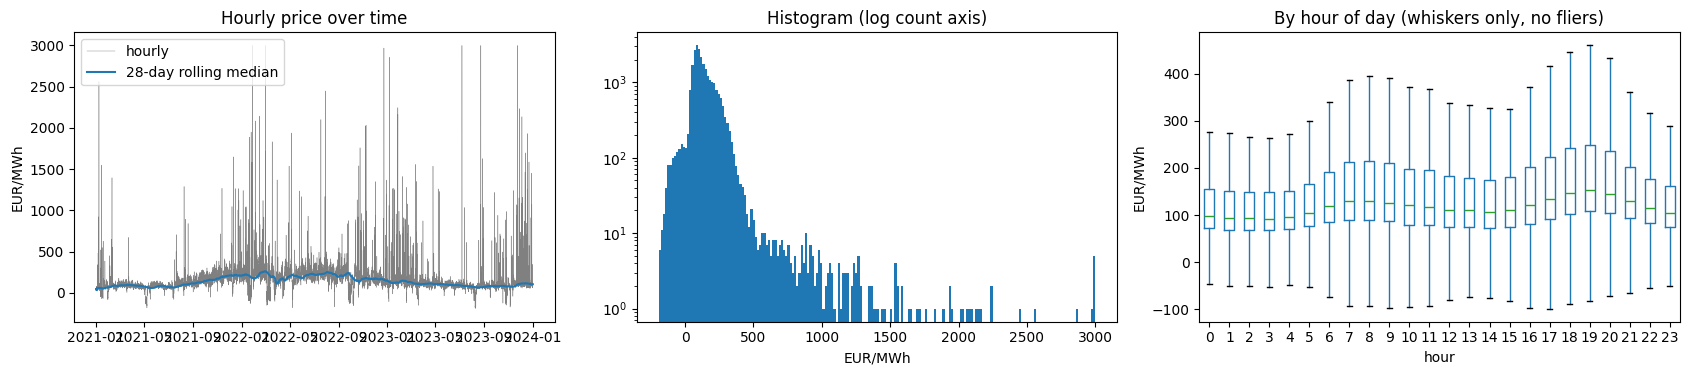

In [10]:
s = prices.set_index('ts_utc')['price_filled']
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(s.index, s.values, lw=0.3, color='grey', label='hourly')
axes[0].plot(s.rolling('28D').median(), color='C0', lw=1.5, label='28-day rolling median')
axes[0].set(title='Hourly price over time', ylabel='EUR/MWh'); axes[0].legend()

axes[1].hist(s, bins=200); axes[1].set_yscale('log')
axes[1].set(title='Histogram (log count axis)', xlabel='EUR/MWh')

prices.boxplot(column='price_filled', by='hour', ax=axes[2], showfliers=False, grid=False)
axes[2].set(title='By hour of day (whiskers only, no fliers)', xlabel='hour', ylabel='EUR/MWh')
fig.suptitle(''); plt.tight_layout(); plt.show()

What the distribution looks like:

- **Regime dependence.** The 2022 median is about twice the 2021 and 2023 medians (the energy crisis). The pooled histogram
  mixes regimes, so part of the apparent right skew is a *level shift*, not within-regime tail behaviour.
- **Heavy tails on both sides.** Excess kurtosis is about 98. On the right, spikes reach the 3000 cap. On the left, about 4% of hours
  are negative, down to -192.
- **Strong intraday shape.** Median prices bottom out overnight (about 93 at 01:00-03:00), peak in the morning (07:00-08:00),
  dip around midday when solar is high, and reach their highest in the evening peak (18:00-20:00, about 150).

So I care less about "the" distribution than about the distribution **conditional on recent level and hour**. That points
to a transformation that also removes the time-varying level.

## 5. Candidate transformations

| candidate | what it is | handles negatives? |
|---|---|---|
| Yeo-Johnson | power transform, λ fit by maximum likelihood (Box-Cox extended to the real line) | yes |
| asinh(raw) | log-like for large \|x\|, linear near 0, symmetric | yes |
| asinh(robust z) | z = (price - trailing median) / trailing MAD, then asinh (Uniejewski, Weron & Ziel 2018) | yes |

The robust z uses the median and MAD of **the previous 28 days only**, so every value is computable at 10:00 on
the day before delivery. The window length is a hyperparameter to revisit in Part B.
Median/MAD rather than mean/std, because the spikes we are trying to tame would inflate a mean/std scale.

The λ below is fitted on the whole sample. That is fine for *description*. In Part B it must be refit inside each walk-forward fold.

In [12]:
def trailing_robust_scale(df, window_days=28):
    # Level/scale for day t use days t-window..t-1 only: what is known when forecasting day t.
    by_day = df.groupby('date')['price_filled'].apply(np.array)
    out = {}
    for i in range(window_days, len(by_day)):
        w = np.concatenate(by_day.iloc[i - window_days:i].values)
        med = np.median(w)
        out[by_day.index[i]] = (med, 1.4826 * np.median(np.abs(w - med)))   # 1.4826*MAD ~ sigma under normality
    return pd.DataFrame.from_dict(out, orient='index', columns=['level', 'scale'])

prices = prices.join(trailing_robust_scale(prices), on='date')
prices['z'] = (prices['price_filled'] - prices['level']) / prices['scale']

sample = prices.dropna(subset=['z']).copy()     # common sample: drop the first 28 days (no history yet)
x = sample['price_filled']
yj, lam = stats.yeojohnson(x)

candidates = {
    'raw': x.values,
    f'Yeo-Johnson (λ={lam:.2f})': yj,
    'asinh(raw)': np.arcsinh(x.values),
    'asinh(robust z)': np.arcsinh(sample['z'].values),
}
pd.DataFrame({k: {'skew': stats.skew(v), 'excess kurtosis': stats.kurtosis(v)}
              for k, v in candidates.items()}).T.round(2)

,skew,excess kurtosis
raw,6.82,97.71
Yeo-Johnson (λ=0.90),3.84,50.27
asinh(raw),-4.25,18.39
asinh(robust z),0.24,1.06


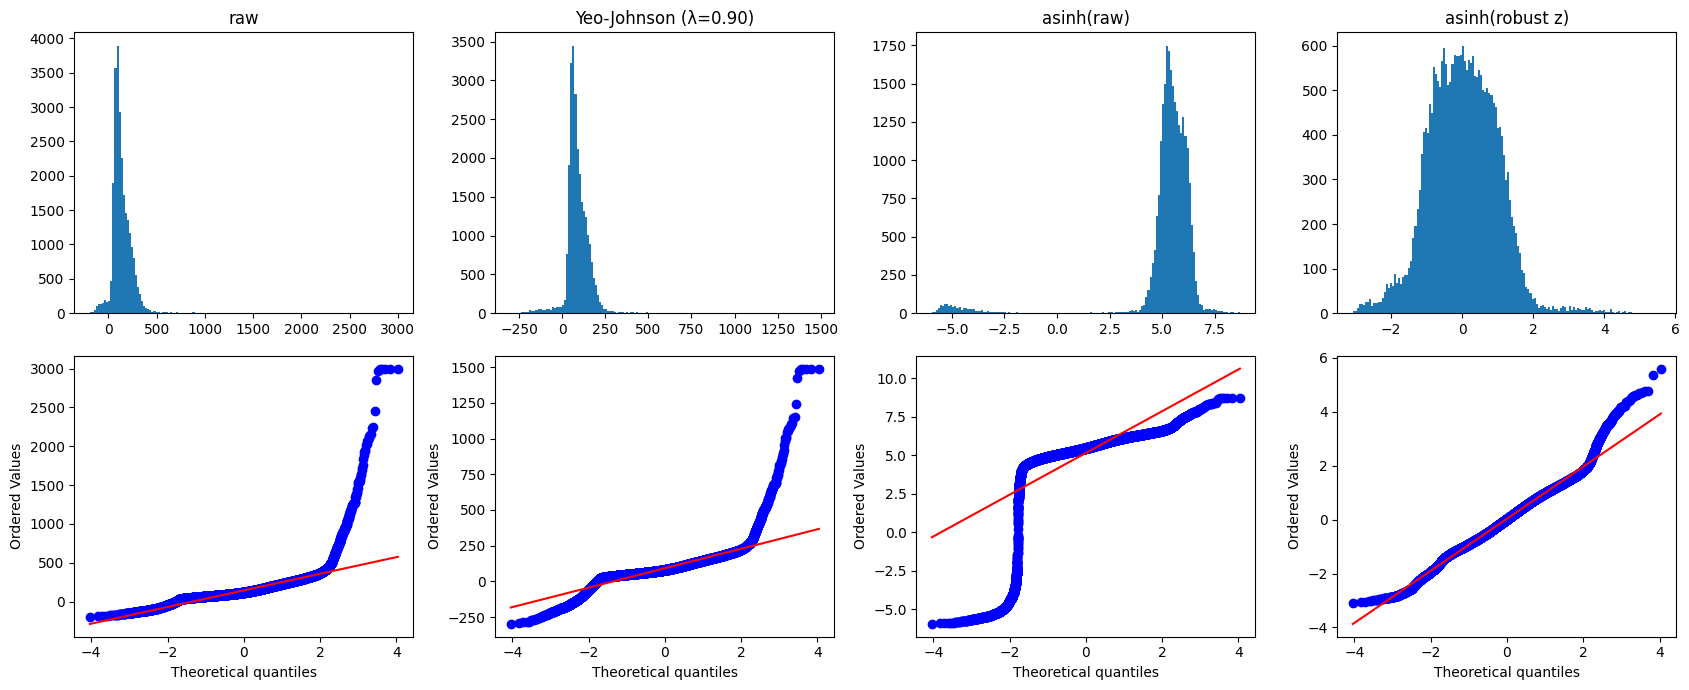

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, (name, v) in enumerate(candidates.items()):
    axes[0, j].hist(v, bins=150); axes[0, j].set_title(name)
    stats.probplot(v, dist='norm', plot=axes[1, j])   # fitted reference line, no need to standardise first
    axes[1, j].set_title('')
plt.tight_layout(); plt.show()

- **Yeo-Johnson** barely changes anything: λ ≈ 0.9 is close to the identity (λ = 1), and kurtosis only halves.
- **asinh(raw)** over-corrects. Positive prices around 100 map to about 5.3 and negative prices around -100 map to about -5.3, so the
  negatives become a separate cluster: the transformed series is bimodal with left skew.
- **asinh(robust z)** is close to Gaussian (skew ≈ 0.2, excess kurtosis ≈ 1). Most of the gain comes from removing the
  time-varying level and scale; asinh then compresses the remaining spikes on both sides.

### Why does Yeo-Johnson refuse to transform?

In [13]:
print(f'λ on all prices:          {stats.yeojohnson(x)[1]:.2f}')
print(f'λ on positive prices only: {stats.yeojohnson(x[x > 0])[1]:.2f}   (≈ 0, i.e. log-like)')
print('λ by year:', {y: round(stats.yeojohnson(v)[1], 2) for y, v in x.groupby(sample['timestamp'].dt.year)})

λ on all prices:          0.90
λ on positive prices only: 0.06   (≈ 0, i.e. log-like)
λ by year: {2021: 0.95, 2022: 0.92, 2023: 0.88}


On positive prices alone, maximum likelihood picks λ ≈ 0.06, essentially a log. Adding the roughly 4% of negative hours pushes λ to about 0.9.

The reason is that Yeo-Johnson applies exponent λ to x ≥ 0 and exponent **2 - λ** to x < 0. Any λ < 1 that compresses the right tail
automatically *stretches* the left tail (2 - λ > 1). The negative tail is already heavy (1% quantile around -70 to -100),
so the likelihood settles near λ = 1.

**A single-parameter power transform can fix skew in one direction, but not heavy tails on both sides.**

### Is the variance stable across regimes?

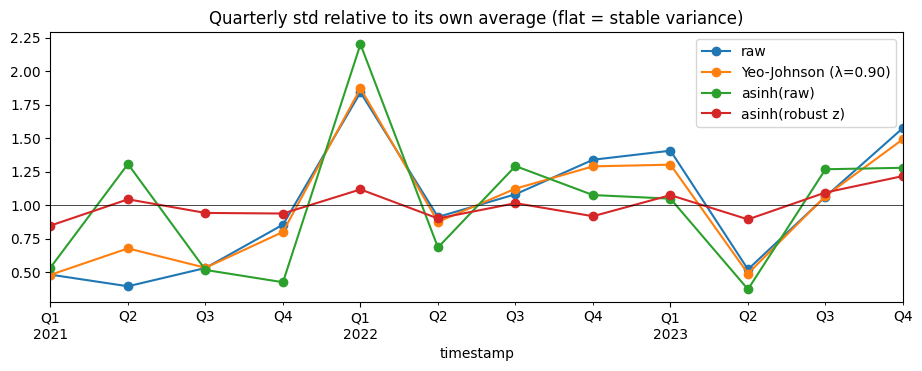

max / min quarterly std: {'raw': 4.67, 'Yeo-Johnson (λ=0.90)': 3.9, 'asinh(raw)': 5.92, 'asinh(robust z)': 1.44}


In [14]:
q = (pd.DataFrame(candidates, index=sample.index)
       .groupby(sample['timestamp'].dt.to_period('Q')).std())
(q / q.mean()).plot(marker='o', title='Quarterly std relative to its own average (flat = stable variance)')
plt.axhline(1, color='k', lw=0.5); plt.show()
print('max / min quarterly std:', (q.max() / q.min()).round(2).to_dict())

Only the robust-z version stabilises the variance across the crisis and post-crisis regimes, because it rescales by recent volatility.
A static transform (Yeo-Johnson, or asinh on raw prices) cannot do that: one fixed curve cannot adapt to a level that moves from about 100 to about 200 and back.

## 6. What any transformation does *not* fix: back-transformation bias

A model fitted with squared loss in transformed space predicts roughly the conditional *mean of the transformed price*.
Inverting that gives roughly the conditional **median** of the price, not its mean. Illustration: for each day, compare the mean
price with the inverse transform of the mean transformed price. Level and scale are constant within a day, so the inverse is exact.

In [15]:
d = (sample.assign(az=np.arcsinh(sample['z']))
           .groupby('date')
           .agg(mean_raw=('price_filled', 'mean'), median_raw=('price_filled', 'median'),
                mean_az=('az', 'mean'), level=('level', 'first'), scale=('scale', 'first')))
d['back_transformed'] = d['level'] + d['scale'] * np.sinh(d['mean_az'])

print(d[['mean_raw', 'median_raw', 'back_transformed']].mean().round(2))
print(f"share of days where back-transformed < mean: {(d.back_transformed < d.mean_raw).mean():.0%}")

gap = d['mean_raw'] - d['back_transformed']
spike_day = sample.groupby('date')['price_filled'].max() > 1000
print(f"mean gap on days with a >1000 spike: {gap[spike_day].mean():.1f}  (n={spike_day.sum()})   other days: {gap[~spike_day].mean():.1f}")

mean_raw            144.35
median_raw          133.46
back_transformed    136.68
dtype: float64
share of days where back-transformed < mean: 61%
mean gap on days with a >1000 spike: 70.9  (n=74)   other days: 3.0


On average the back-transformed value is close to the median and about 8 EUR/MWh below the mean, and it falls below the daily mean
on most days. The gap is concentrated on spike days: about 71 EUR/MWh on days with a spike above 1000, versus about 3 on other days.
Those are exactly the days that matter most for trading. Consequences:

- If you evaluate with **MAE**, this is harmless: the median is the MAE-optimal point forecast.
- If you evaluate with **RMSE**, or the P&L depends on the mean (for example the baseload average), forecasts are biased low.
  Either pick the metric deliberately, or apply a bias correction (for example Duan's smearing estimator).
- Always report errors **in EUR/MWh**, not in transformed units, so transformed and untransformed models are comparable.

## 7. Answer to A1

**Distribution.** Hourly prices are strongly right-skewed with heavy tails on *both* sides: excess kurtosis is about 98, spikes reach the
3000 EUR/MWh cap, and about 4% of hours are negative, down to -192. The level is non-stationary: the 2022 median is about twice that of 2021 and 2023.
There is also a strong intraday shape.

**Data issues handled first** (a transformation does not fix these):

| issue | evidence | action |
|---|---|---|
| 18 hours at -9999 | sentinel, below the -500 floor; each fails reconciliation | reconstructed exactly from the vendor daily average (error ≤ 0.12), flagged |
| 3 duplicated local timestamps | October DST fall-back | added a UTC key |
| 5 hours at exactly 3000 | round maximum; they reconcile | kept as real but censored, flagged |
| spikes > 1000, negative prices | reconcile; negatives coincide with about 4x renewables | kept as genuine market behaviour |
| weather file in UTC | starts 23:00 on 31 Dec; solar peaks at local noon only after converting | convert before any join |

**Transformation.** I would model `asinh((price - trailing 28-day median) / trailing 28-day MAD)`.

- *What it fixes:* it compresses the tails on both sides, it removes the regime-dependent level and scale (quarterly std ratio
  about 1.4 versus about 4.7 for raw prices), and it gives a near-Gaussian target, so a squared-error loss is not dominated by a handful of spike hours.
  It uses only information available at forecast time.
- *What it does not fix:* data errors (handled above); autocorrelation, daily and weekly seasonality (left for the features and model);
  censoring at the cap; regime breaks faster than the 28-day window can follow; and back-transformation bias (the forecast is about the median,
  which matters for RMSE or mean-based P&L).
- *Why not Yeo-Johnson:* with negative prices present, maximum likelihood picks λ ≈ 0.9, close to the identity, because any compression of the right
  tail stretches the left. It is also static, so it cannot follow regime changes.
- *Trade-off to state openly:* compressing spikes down-weights exactly the hours where trading P&L can be largest. Whether that is
  desirable depends on the objective.

**How the choice will be validated.** In Part B the transformation is treated like a hyperparameter. The same model is run in walk-forward with
(a) raw prices, (b) Yeo-Johnson and (c) robust asinh, with any fitted parameters (λ, window) estimated inside each training fold. Errors are compared
in EUR/MWh, overall and separately on spike and negative-price hours.